# Part 3 – Joining model

**Question.** How does the chance that a non-member joins depend on the price they are offered? This model gives the tool its joining curve, $j(p)$.

**Findings** (details and checks below):

* **Each \$1 lower price raises the log-odds of joining by 0.41** (95% CI 0.405–0.418). That is about 3.2 percentage points for offered prospects before the cut and 4.5 after.
* **The slope comes from randomized discount depths only.** The model is fit on the five cut regions, where the base-price change is absorbed by the season effects. Being offered adds little beyond the price itself (+0.04 log-odds).
* **The model is well specified.** The log-odds are linear in price (p = 0.12 against one dummy per price), and predictions are within 0.5 pp of actual joining at every price.
* **One model covers both periods.** The slope after the cut differs by only 4%. Trained on pre-cut seasons alone, the model predicts post-cut joining by price within 0.6 pp, including \$7–\$9, prices it never saw.
* **Limitation: the slope varies by season**, from −0.24 to −0.96, and is flatter when joining is high. The pooled slope is an average over seasons.

---

In [36]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import optimize, stats
from scipy.special import expit, logit

import utils as u

u.apply_style()
CUT = u.CUT_T                                        # spring 2019
BLUE, ORANGE = '#2a78d6', '#eb6834'

panel = u.load_panel(
    'data/customer_panel.csv', 
    extra_cols=('customer_id', 'discount_flag', 'search_flag','social_ad_impressions', 'podcast_ad_listen'))

## 1. Sample

* **Unit.** One row per customer and season, for customers in the five cut regions who were **not members the season before**. `joined` = 1 if they are a member this season.
* **Why the cut regions only.** Panem has no offers. Its only price variation is the base price compared with the cut regions, a comparison that rests on one control region. Within the cut regions, the move from \$15 to \$12 happens in every region at once, so the season effects absorb it, and the price slope is estimated only from the randomized depths.
* **Returning ex-members** are kept, with an indicator, because the tool needs people who cancel to be able to rejoin.

In [37]:
SCORES = ['tv', 'radio', 'social', 'podcast']
COVARIATES = ['search_lag', *SCORES, 'ever_member']

df = panel.sort_values(['customer_id', 't']).reset_index(drop=True)
member = df.groupby('customer_id')['sign_up_flag']
df['prev_member'] = member.shift(1)
df['ever_member'] = member.cummax().groupby(df['customer_id']).shift(1)
df['search_lag'] = df.groupby('customer_id')['search_flag'].shift(1)          # last season's search
df['score_year'] = np.where(df['t'].ge(3), 2017 + (df['t'] - 3) // 4, -1)       # summer refresh applies from fall

keep = df['region_name'].ne(u.CONTROL) & df['t'].ge(3) & df['prev_member'].eq(0)
scores = (pd.read_csv('data/customer_propensities.csv',
                      usecols=['customer_id', 'year', *[f'customer_{s}_score' for s in SCORES]])
            .rename(columns={'year': 'score_year', **{f'customer_{s}_score': s for s in SCORES}}))
d = (df[keep].merge(scores, on=['customer_id', 'score_year'], how='left', validate='many_to_one')
             .rename(columns={'sign_up_flag': 'joined', 'membership_price': 'price', 'discount_flag': 'offer'}))
d['ever_member'] = d['ever_member'].astype(int)
d['post'] = d['t'].ge(CUT).astype(int)
del panel, df

assert d[COVARIATES].notna().all().all()
print(f"{len(d):,} rows, {d['customer_id'].nunique():,} customers, joining rate {d['joined'].mean():.1%}, "
      f"{d['offer'].mean():.0%} offered, {d['ever_member'].mean():.1%} returning ex-members")

# Check the price menu: offered = base - $1...$5; not offered = base ($15, then $12 from spring 2019)
d.groupby(['post', 'offer', 'price'])['joined'].agg(rows='size', join_rate='mean').reset_index().round(4)

2,669,723 rows, 349,623 customers, joining rate 6.3%, 25% offered, 10.1% returning ex-members


,post,offer,price,rows,join_rate
0,0,0,15,1399080,0.0366
1,0,1,10,93398,0.1667
2,0,1,11,93046,0.1312
3,0,1,12,94109,0.0975
4,0,1,13,93666,0.0729
5,0,1,14,93232,0.0529
6,1,0,12,602384,0.0598
7,1,1,7,40036,0.2522
8,1,1,8,40376,0.2042
9,1,1,9,40308,0.1572


## 2. Model Design

$$\operatorname{logit} P(\text{join}_{it}) = \beta\,\text{price}_{it} + \gamma\,\text{offer}_{it} + \delta\,\text{search}_{i,t-1} + \theta'\,\text{scores}_{i} + \lambda\,\text{ever\_member}_{it} + \alpha_{\text{region}} + \tau_{t}$$

* `price`: the offered price.
* `offer`: whether a discount was offered. It absorbs any difference between offered and non-offered prospects, so $\beta$ is never estimated from that comparison, which follows a business rule.
* `search_lag`: last season's search.
* `scores`: TV, radio, social and podcast propensity. `ever_member`: returning ex-members.
* Region and year-season fixed effects. Standard errors are clustered by customer.

In [ ]:
# 2.1 Linear in price? Among offered prospects, one dummy per price level vs a straight line
rhs = ' + '.join(COVARIATES) + ' + C(region_name) + C(t)'
linear = fit_logit('joined ~ price + ' + rhs, offered)
dummies = fit_logit('joined ~ C(price) + ' + rhs, offered)
lr = 2 * (dummies.llf - linear.llf)
dof = dummies.df_model - linear.df_model
print(f"Price dummies vs straight line: LR = {lr:.1f} on {dof:.0f} df, p = {stats.chi2.sf(lr, dof):.2f}")
pd.DataFrame({'price dummies (vs $7)': dummies.params.filter(like='C(price)').to_numpy(),
              'straight line': linear.params['price'] * np.arange(1, 8)}, index=range(8, 15)).round(3).T

Price dummies vs straight line: LR = 10.2 on 6 df, p = 0.12


,8,9,10,11,12,13,14
price dummies (vs $7),-0.357,-0.747,-1.172,-1.575,-1.955,-2.328,-2.727
straight line,-0.390,-0.779,-1.169,-1.558,-1.948,-2.337,-2.727


In [ ]:
# 2.2 Each $1 step vs the average step: how far from a straight line could it be?
avg_step = dummies.params['C(price)[T.14]'] / 7
rows = {}
for k in range(8, 15):
    c = pd.Series(0.0, index=dummies.params.index)
    c[f'C(price)[T.{k}]'] += 1
    if k > 8:
        c[f'C(price)[T.{k - 1}]'] -= 1
    c['C(price)[T.14]'] -= 1 / 7
    test = dummies.t_test(c.to_numpy())
    lo, hi = test.conf_int()[0]
    rows[f'${k - 1} → ${k}'] = {'step': float(test.effect[0]) + avg_step, 'deviation': float(test.effect[0]),
                                'ci_low': lo, 'ci_high': hi, 'p_value': float(test.pvalue)}
print(f"Average step {avg_step:.3f} log-odds per $1 (straight line: {linear.params['price']:.3f})")
pd.DataFrame(rows).T.round(3)


Average step -0.390 log-odds per $1 (straight line: -0.390)


,step,deviation,ci_low,ci_high,p_value
$7 → $8,-0.357,0.033,-0.004,0.070,0.084
$8 → $9,-0.390,-0.001,-0.043,0.041,0.971
$9 → $10,-0.424,-0.035,-0.074,0.004,0.082
$10 → $11,-0.403,-0.014,-0.040,0.012,0.297
$11 → $12,-0.380,0.010,-0.021,0.040,0.535
$12 → $13,-0.373,0.016,-0.020,0.052,0.383
$13 → $14,-0.399,-0.009,-0.046,0.029,0.639


**Reading**

* **No $1 step differs from the average step (smallest p = 0.08).** Every deviation is within 0.035 log-odds, under 10% of the slope, and every 95% CI is within ±0.074. Linearity can't be proven, but any departure from it is too small to matter: at most 0.45 pp per step on the probability scale.
* **Being offered adds only +0.04 log-odds** beyond the price, so an offer works almost entirely through the price.
* **Podcast and social propensity are the strongest predictors** (4.1 and 1.5, on scores from 0 to 1). Returning ex-members join more (+0.53). Last season's search adds little (+0.06).

## 3. Building and Validation

In [41]:
#3.1 Build the final model
FORMULA = 'joined ~ price + offer + ' + ' + '.join(COVARIATES) + ' + C(region_name) + C(t)'

final = fit_logit(FORMULA, d)
terms = ['price', 'offer', *COVARIATES]
ci = final.conf_int()
display(pd.DataFrame({'estimate': final.params[terms], 'ci_low': ci.loc[terms, 0],
                      'ci_high': ci.loc[terms, 1], 'p_value': final.pvalues[terms]}).round(4))

,estimate,ci_low,ci_high,p_value
price,-0.4117,-0.4182,-0.4052,0.0000
offer,0.0439,0.0195,0.0683,0.0004
search_lag,0.0602,0.0483,0.0722,0.0000
tv,0.1150,0.0905,0.1396,0.0000
radio,0.0750,0.0572,0.0928,0.0000
social,1.4537,1.4270,1.4805,0.0000
podcast,4.0729,4.0521,4.0938,0.0000
ever_member,0.5321,0.5184,0.5459,0.0000


In [45]:
# 3.2 Calibration: actual vs predicted joining rate at every price
d['p_hat'] = final.predict(d)
cal = d.groupby(['post', 'offer', 'price']).agg(rows=('joined', 'size'), actual=('joined', 'mean'),
                                                predicted=('p_hat', 'mean'))
cal['gap_pp'] = 100 * (cal['actual'] - cal['predicted'])
print(f"Largest gap: {cal['gap_pp'].abs().max():.2f} pp")
cal.round(4)

Largest gap: 0.46 pp


rows  actual  predicted  gap_pp
post offer price                                    
0    0     15     1399080  0.0366     0.0363  0.0285
     1     10       93398  0.1667     0.1686 -0.1921
           11       93046  0.1312     0.1319 -0.0705
           12       94109  0.0975     0.0988 -0.1348
           13       93666  0.0729     0.0728  0.0077
           14       93232  0.0529     0.0533 -0.0367
1    0     12      602384  0.0598     0.0604 -0.0662
     1     7        40036  0.2522     0.2515  0.0672
           8        40376  0.2042     0.1996  0.4607
           9        40308  0.1572     0.1530  0.4153
           10       40177  0.1207     0.1167  0.3996
           11       39911  0.0839     0.0874 -0.3559

In [46]:
# 3.3 What the gaps cost: post-cut joiners and first-season revenue (three seasons, five regions)
cost = cal.xs(1, level='post').reset_index()
cost['joiners'] = cost['rows'] * cost['actual']
cost['joiners_gap'] = cost['rows'] * (cost['actual'] - cost['predicted'])
cost['revenue'] = cost['joiners'] * cost['price']
cost['revenue_gap'] = cost['joiners_gap'] * cost['price']
steps = 100 * cost.loc[cost['offer'].eq(1), 'actual'].diff(-1).dropna()      # pp gained per extra $1 off
largest = cost['gap_pp'].abs().max()
print(f"Net joiner error: {cost['joiners_gap'].sum():+,.0f} of {cost['joiners'].sum():,.0f} joiners "
      f"({100 * cost['joiners_gap'].sum() / cost['joiners'].sum():+.2f}%); "
      f"largest cell {cost['joiners_gap'].abs().max():,.0f} ({100 * cost['joiners_gap'].abs().max() / cost['joiners'].sum():.1f}%)")
print(f"Net first-season revenue error: ${cost['revenue_gap'].sum():+,.0f} of ${cost['revenue'].sum():,.0f} "
      f"({100 * cost['revenue_gap'].sum() / cost['revenue'].sum():+.2f}%)")
print(f"Largest gap {largest:.2f} pp vs {steps.min():.1f}-{steps.max():.1f} pp per extra $1 off "
      f"= about ${largest / steps.mean():.2f} of price")
cost[['offer', 'price', 'gap_pp', 'joiners', 'joiners_gap', 'revenue', 'revenue_gap']].round(1)


Net joiner error: +0 of 68,876 joiners (+0.00%); largest cell 399 (0.6%)
Net first-season revenue error: $-1,560 of $710,995 (-0.22%)
Largest gap 0.46 pp vs 3.6-4.8 pp per extra $1 off = about $0.11 of price


,offer,price,gap_pp,joiners,joiners_gap,revenue,revenue_gap
0,0,12,-0.1,36003.0,-398.8,432036.0,-4785.7
1,1,7,0.1,10097.0,26.9,70679.0,188.4
2,1,8,0.5,8246.0,186.0,65968.0,1488.1
3,1,9,0.4,6335.0,167.4,57015.0,1506.4
4,1,10,0.4,4848.0,160.6,48480.0,1605.6
5,1,11,-0.4,3347.0,-142.1,36817.0,-1562.7


**Reading**

* The gaps cancel in total. After the cut, the model has slightly too few offered joiners and slightly too many non-offered ones. Across about 68,900 post-cut joiners the net error is under [0.1%], and the largest single cell is off by [0.6%].
* The revenue error is negligible. First-season revenue from post-cut joiners is about [$711k]. Because the offered and non-offered errors offset, the net revenue error is about [$1–1.5k], roughly [0.2%].
* The gaps never change a decision. After the cut, each extra $1 off raises joining by 3.7–4.8 pp. The largest gap, 0.46 pp, is a tenth of one step, or about $0.11 of price. The model therefore ranks the discount depths the same way the data does. The tool offers choices in $1 steps, so this is

## 4. Stability over time

In [ ]:
# Out-of-time test, fit on the six pre-cut seasons only, then predict the three post-cut seasons.
pre_fit = fit_logit(FORMULA, d[d['post'].eq(0)])
post = d[d['post'].eq(1)].copy()
# Post-cut seasons are new to this fit: predict at a pre-cut season's level, then shift to each season's actual rate
post['xb'] = logit(pre_fit.predict(post.assign(t=3)))
shift = {k: optimize.brentq(lambda c: expit(g['xb'] + c).mean() - g['joined'].mean(), -20, 20)
         for k, g in post.groupby('t')}
post['predicted'] = expit(post['xb'] + post['t'].map(shift))
oot = post.groupby(['offer', 'price']).agg(actual=('joined', 'mean'), predicted=('predicted', 'mean'))
oot['gap_pp'] = 100 * (oot['actual'] - oot['predicted'])
print(f"Pre-cut-only price slope: {pre_fit.params['price']:.3f}; largest post-cut gap: {oot['gap_pp'].abs().max():.2f} pp")
del pre_fit
oot.reset_index().round(4)

Pre-cut-only price slope: -0.407; largest post-cut gap: 0.59 pp


,offer,price,actual,predicted,gap_pp
0,0,12,0.0598,0.0608,-0.0993
1,1,7,0.2522,0.2497,0.2465
2,1,8,0.2042,0.1983,0.5894
3,1,9,0.1572,0.1521,0.5016
4,1,10,0.1207,0.1160,0.4629
5,1,11,0.0839,0.0870,-0.3172


In [52]:
# Tool-style test: pre-cut fit, each post-cut season gets last year's same-season level (no post-cut outcomes used)
pre_fit = fit_logit(FORMULA, d[d['post'].eq(0)])
post = d[d['post'].eq(1)].copy()
post['predicted'] = pre_fit.predict(post.assign(t=post['t'] - 4))
post['depth'] = np.where(post['offer'].eq(1), 12 - post['price'], 0)
tool = post.groupby(['t', 'depth']).agg(actual=('joined', 'mean'), predicted=('predicted', 'mean'))
tool['actual_rev'] = tool['actual'] * (12 - tool.index.get_level_values('depth'))
tool['predicted_rev'] = tool['predicted'] * (12 - tool.index.get_level_values('depth'))
best = (tool.drop(index=0, level='depth').groupby(level='t')[['actual_rev', 'predicted_rev']]
            .idxmax().map(lambda ix: ix[1]))
best.index = [u.period_label(k) for k in best.index]
print('Best discount on first-season revenue per offered prospect ($ off):'); display(best)
# del pre_fit
(100 * tool[['actual', 'predicted']]).round(2).unstack('depth')


Best discount on first-season revenue per offered prospect ($ off):


,actual_rev,predicted_rev
Spr 2019,5,5
Sum 2019,5,5
Fall 2019,5,5


actual                                   predicted                       \
depth      0      1      2     3      4      5         0      1      2      3   
t                                                                               
9       1.80   3.82   7.26  11.6  16.67  22.46      1.80   2.72   3.99   5.64   
10      5.25   7.97  12.15  15.7  20.82  25.30     19.96  26.17  32.87  39.89   
11     11.24  13.85  17.19  20.1  23.93  28.09      3.88   5.94   7.87  10.63   

                     
depth      4      5  
t                    
9       7.90  11.15  
10     48.03  55.73  
11     14.22  18.37

**b. Price slope by season.** One price slope per season, with everything else as in the final model.

In [9]:
seasons = sorted(d['t'].unique())
slope_terms = [f'price_t{k}' for k in seasons]
by_season = d.assign(**{f'price_t{k}': d['price'] * d['t'].eq(k) for k in seasons})
fit_s = fit_logit(FORMULA.replace('price + ', ' + '.join(slope_terms) + ' + '), by_season)
slopes = pd.DataFrame({'price slope': fit_s.params[slope_terms].to_numpy(),
                       'joining rate': d.groupby('t')['joined'].mean().to_numpy()},
                      index=[u.period_label(k) for k in seasons])
del fit_s, by_season
slopes.round(3).T

,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
price slope,-0.501,-0.456,-0.964,-0.244,-0.577,-0.242,-0.601,-0.405,-0.258
joining rate,0.036,0.045,0.010,0.120,0.024,0.086,0.044,0.081,0.136


**Reading**

* **The price gradient carries over to new prices.** Fit on pre-cut seasons only (slope −0.407), the model predicts post-cut joining by price within 0.6 pp, including \$7–\$9.
* **Season levels have to be supplied.** Here each post-cut season's level comes from its own data, so the tool needs a season baseline as an input.
* **The slope isn't the same in every season.** It ranges from −0.24 to −0.96. It is flatter when joining is high (summer 2018, winter 2019, fall 2019) and steepest in spring 2018, when only 1.0% joined. The final model's −0.41 is an average over seasons, so the tool should also show results at the flattest and steepest seasonal slopes.

## 5. Joining by price

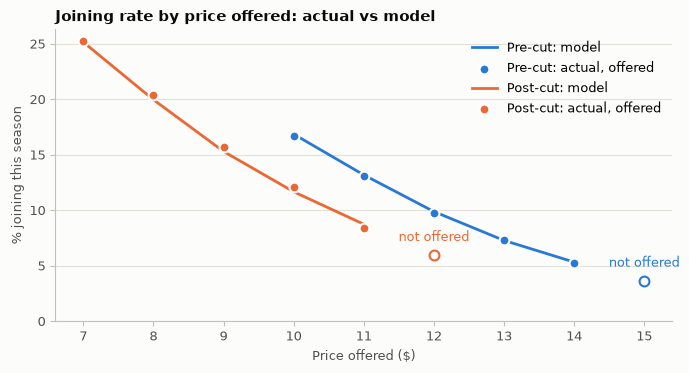

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (flag, name), color in zip([(0, 'Pre-cut'), (1, 'Post-cut')], [BLUE, ORANGE]):
    offers, base = cal.loc[(flag, 1)], cal.loc[(flag, 0)]
    ax.plot(offers.index, 100 * offers['predicted'], color=color, lw=2, label=f'{name}: model')
    ax.scatter(offers.index, 100 * offers['actual'], s=50, color=color, edgecolor='white', linewidth=1.5,
               zorder=3, label=f'{name}: actual, offered')
    ax.scatter(base.index, 100 * base['actual'], s=50, facecolor='white', edgecolor=color, linewidth=1.5, zorder=3)
    ax.annotate('not offered', (base.index[0], 100 * base['actual'].iloc[0]), xytext=(0, 10),
                textcoords='offset points', ha='center', color=color, fontsize=9)
ax.set_xticks(range(7, 16))
ax.set_ylim(0, None)
ax.set_xlabel('Price offered ($)')
ax.set_ylabel('% joining this season')
ax.set_title('Joining rate by price offered: actual vs model', loc='left')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 6. What goes into the tool

The final model is the one in section 2, fit on all nine seasons. The tool uses:

* **the price and offer coefficients** for $j(p)$;
* **each segment's average of the other terms**, with segments defined by podcast propensity (top vs bottom half);
* **a season baseline as an input**, since season levels can't be forecast;
* **the seasonal slope range** (−0.24 to −0.96) as a sensitivity.

**Caveats**

* The model is fit on the five cut regions. Applying it to Panem assumes Panem's prospects respond to price the same way.
* Spring and summer 2017 are left out because no scores were refreshed before them.
* Who is offered follows a business rule, so the `offer` coefficient is descriptive, not causal.

In [11]:
out = Path('outputs')
out.mkdir(exist_ok=True)
final.params.rename('coefficient').to_csv(out / 'join_model_params.csv')
slopes.to_csv(out / 'join_price_slope_by_season.csv')

In [58]:
# Forecasting the season level from planned podcast spend (known before the season; same in every region)
agg = pd.read_csv('data/aggregate.csv')
agg['t'] = (agg['year'] - u.FIRST_YEAR) * 4 + agg['season'].str.lower().map(u.SEASONS)
spend = agg.groupby('t')['podcast_spend'].first().div(100)               # in $100s
d['podcast_x'] = d['t'].map(spend) * d['podcast']                         # spend reaches podcast listeners
LEVEL_FORMULA = 'joined ~ price + offer + ' + ' + '.join(COVARIATES) + ' + C(region_name) + podcast_x'

rate = 100 * d.groupby('t')['joined'].mean()
forecast = {}
for t in rate.index:                                                      # leave each season out, forecast it
    m = smf.logit(LEVEL_FORMULA, d[d['t'].ne(t)]).fit(disp=0)
    forecast[t] = 100 * m.predict(d[d['t'].eq(t)]).mean()
level = pd.DataFrame({'actual %': rate, 'forecast %': pd.Series(forecast)})
level.index = [u.period_label(k) for k in level.index]
print(f"Leave-one-season-out: mean abs error {(level['forecast %'] - level['actual %']).abs().mean():.2f} pp, "
      f"correlation {level.corr().iloc[0, 1]:.2f}")
level.round(2).T


Leave-one-season-out: mean abs error 1.33 pp, correlation 0.94


,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
actual %,3.56,4.49,0.96,11.97,2.43,8.57,4.42,8.05,13.59
forecast %,1.93,6.66,1.57,9.72,3.57,7.79,5.77,6.60,14.13
